# Validation 2-2 : Global Matrix Confusion 

## 1- Imports and Setup

In [1]:
import numpy as np
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

## 2- Load Data

Here, we load the data from the provided CSV files.

In [2]:
tool_df = pd.read_csv('result_tool.csv')
manual_df = pd.read_csv('manual_labeling.csv')

## 3- Create a Global Confusion Matrix

In [3]:
global_cm = np.zeros((2, 2))  # 2x2 for binary classification

## 4- Define Code Smells List

In [5]:
code_smells_list = [
    'LC', 
    'LEC', 
    'CCC', 
    'LE', 
    'CIC'
]

## 5- Generate and Aggregate Confusion Matrices

For each specific code smell, compute the confusion matrix and then sum these individual matrices to produce a global matrix.

In [6]:
for smell in code_smells_list:
    tool_labels = tool_df[smell]
    manual_labels = manual_df[smell]

    # Compute the confusion matrix
    cm = confusion_matrix(manual_labels, tool_labels)

    # Add the computed matrix to the global matrix
    global_cm += cm

global_cm = global_cm.astype(int)

## 6- Display the Global Confusion Matrix

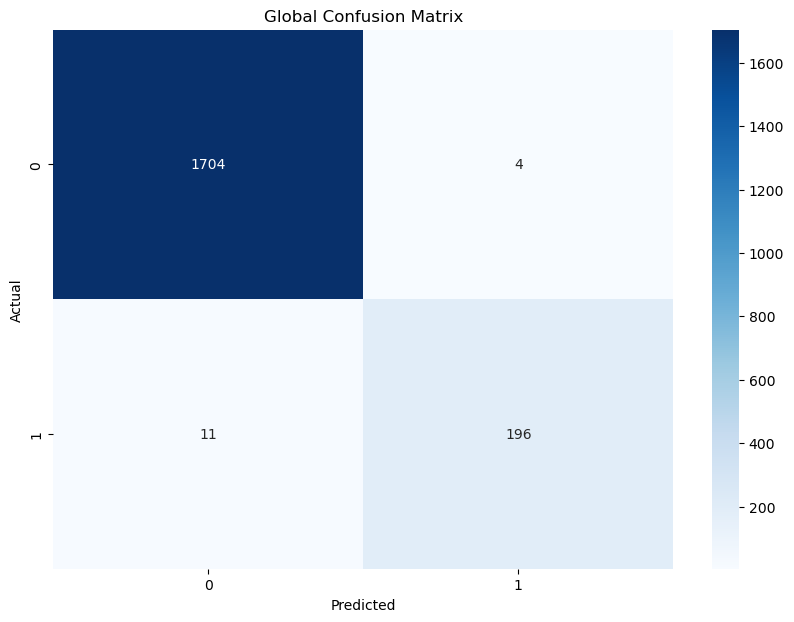

In [7]:
plt.figure(figsize=(10, 7))
sns.heatmap(global_cm, annot=True, fmt='d', cmap='Blues')
plt.title("Global Confusion Matrix")
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()